# Figure 1: schematic of the measures

## Setup

In [1]:
import re
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Circle, FancyBboxPatch, FancyArrowPatch

warnings.filterwarnings("ignore")
%matplotlib inline

def _root(start=None):
    # package root = the folder that holds Data/
    here = Path(__file__).resolve() if "__file__" in globals() else Path.cwd().resolve()
    for c in (here, *here.parents):
        if (c / "Data" / "conversation_turns.csv").exists():
            return c
    raise RuntimeError(f"cannot find the package root (no Data/conversation_turns.csv at or above {here})")

ROOT   = _root()
CLEAN  = ROOT / "Data"
FIGDIR = ROOT / "Code" / "_output" / "figures"; FIGDIR.mkdir(parents=True, exist_ok=True)
RESDIR = ROOT / "Code" / "_output" / "results"; RESDIR.mkdir(parents=True, exist_ok=True)

COL = {"partner": "#00798C", "own": "#D1495B", "solo": "#2B4C7E",
       "grey": "#6E6E6E", "light": "#BFBFBF", "third": "#E8871A"}
SINGLE, DOUBLE = 3.46, 7.09

mpl.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 6.5, "axes.labelsize": 7, "axes.titlesize": 7.5,
    "xtick.labelsize": 6.5, "ytick.labelsize": 6.5, "legend.fontsize": 6,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "lines.linewidth": 1.3, "lines.markersize": 3.5,
    "figure.dpi": 150, "savefig.dpi": 600, "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02, "pdf.fonttype": 42, "ps.fonttype": 42,
})

def panel(ax, letter):
    # place the letter against the drawn (equal-aspect) axes position
    fg = ax.figure; fg.canvas.draw()
    bb = ax.get_position(original=False)
    fg.text(bb.x0, bb.y1 + .010, letter, fontsize=8, fontweight="bold",
            va="bottom", ha="left")

def close_corner(fig):
    for ax in fig.axes:
        if not ax.axison:
            continue
        for get_lim, set_lim, ticks_of, data_lo in (
                (ax.get_xlim, ax.set_xlim, ax.get_xticks, lambda: ax.dataLim.x0),
                (ax.get_ylim, ax.set_ylim, ax.get_yticks, lambda: ax.dataLim.y0)):
            lo, hi = get_lim()
            if hi <= lo:
                continue
            inside = [t for t in ticks_of() if lo <= t <= hi]
            if not inside:
                continue
            first = min(inside)
            if first <= lo:
                continue
            d = data_lo()
            if d != d or d < first + (hi - lo) * 0.03:
                continue
            set_lim(first, hi)
        ax.spines["left"].set_bounds(*ax.get_ylim())
        ax.spines["bottom"].set_bounds(*ax.get_xlim())

def save(fig, name):
    fig.savefig(FIGDIR / f"{name}.pdf")
    fig.savefig(FIGDIR / f"{name}.tif", dpi=300, pil_kwargs={"compression": "tiff_lzw"})
    print(f"wrote {name}.pdf and .tif to Code/_output/figures/")

## Example words

In [2]:
stim = pd.read_csv(CLEAN / "stimuli.csv")

# three of the ten study lists
L_NIGHT, L_AIR, L_CHAIR = 1, 4, 5

# English translations of the Spanish stimuli shown in the figure
ENGLISH = {"día": "day", "luna": "moon", "noche": "night",
           "viento": "wind", "respirar": "breathe", "oxígeno": "oxygen",
           "fresco": "fresh", "aire": "air",
           "asiento": "seat", "taburete": "stool", "sillón": "armchair", "silla": "chair"}

def eng(spanish):
    if spanish not in ENGLISH:
        raise KeyError(f"no translation for {spanish!r}; add it to ENGLISH")
    return ENGLISH[spanish]

def words(lst, wanted):
    # check each Spanish form against the stimulus table for that list
    have = set(stim.loc[stim["list"] == lst, "word"])
    missing = [w for w in wanted if w not in have]
    if missing:
        raise ValueError(f"list {lst} does not contain {missing}")
    return [eng(w) for w in wanted]

def lure_of(lst):
    sp = stim.loc[(stim["list"] == lst) & (stim["is_lure"]), "word"].iloc[0]
    return eng(sp)

# the example intrusion must belong to none of the ten lists
INTRUSION = "guitar"
assert not (stim["word"].str.lower() == "guitarra").any(), "pick another intrusion"

NIGHT = words(L_NIGHT, ["día", "luna"]);           NIGHT_LURE = lure_of(L_NIGHT)
AIR   = words(L_AIR,   ["viento", "respirar", "oxígeno", "fresco"])
CHAIR = words(L_CHAIR, ["asiento", "taburete", "sillón"])
print("night:", NIGHT, "+ lure", NIGHT_LURE)
print("air  :", AIR)
print("chair:", CHAIR)

night: ['day', 'moon'] + lure night
air  : ['wind', 'breathe', 'oxygen', 'fresh']
chair: ['seat', 'stool', 'armchair']


## Drawing helpers

In [3]:
LIST_COL = {L_NIGHT: COL["solo"], L_AIR: COL["partner"], L_CHAIR: COL["third"]}

def token(ax, x, y, word, colour, kind="word", fs=6.0, ws=1.0, h=0.42):
    # kind: word | lure | intrusion | pass; ws scales the box width
    w = (max(0.62, 0.135 * len(word) + 0.30)) * ws
    face = "white" if kind in ("lure", "intrusion", "pass") else colour
    edge = COL["grey"] if kind in ("intrusion", "pass") else colour
    ls = (0, (1.6, 1.2)) if kind == "lure" else "solid"
    ax.add_patch(FancyBboxPatch((x, y - h / 2), w, h,
                                boxstyle="round,pad=0,rounding_size=0.07",
                                linewidth=1.1, linestyle=ls, edgecolor=edge,
                                facecolor=face, zorder=2))
    ax.text(x + w / 2, y, word, ha="center", va="center", fontsize=fs, zorder=3,
            color="white" if face != "white" else edge)
    return x + w

def bracket(ax, x0, x1, y, label, colour, drop=0.13, fs=5.8):
    ax.plot([x0, x0, x1, x1], [y + drop, y, y, y + drop],
            lw=1.0, color=colour, clip_on=False, zorder=1)
    ax.text((x0 + x1) / 2, y - 0.07, label, ha="center", va="top",
            fontsize=fs, color=colour)

def arrow(ax, x0, y0, x1, y1, colour, style="-|>", lw=1.0, rad=0.0):
    ax.add_patch(FancyArrowPatch((x0, y0), (x1, y1), arrowstyle=style,
                                 mutation_scale=7, linewidth=lw, color=colour,
                                 connectionstyle=f"arc3,rad={rad}", zorder=4))

def callout(ax, x, y_box_top, text, colour, top, fs=5.8):
    ax.plot([x, x], [y_box_top + 0.04, top - 0.03], lw=0.9, color=colour, zorder=1)
    ax.text(x, top, text, ha="center", va="bottom", fontsize=fs, color=colour)

def schematic(ax, xlim, ylim):
    ax.set_xlim(*xlim); ax.set_ylim(*ylim); ax.axis("off")
    ax.set_aspect("equal", adjustable="box")

## Panel a · Foraging analogy

In [4]:
def draw_analogy(ax):
    CEN = [(17, 72), (50, 85), (83, 69)]
    TAKE = [2, 2, 3]
    CC = [LIST_COL[L_NIGHT], LIST_COL[L_AIR], LIST_COL[L_CHAIR]]
    for k, ((cx, cy), n_) in enumerate(zip(CEN, TAKE)):
        ax.add_patch(Circle((cx, cy), 11.5, facecolor=CC[k], alpha=.13,
                            edgecolor=CC[k], lw=1.1, zorder=1))
        # five items per bush; filled = taken
        for b in range(5):
            an = 2 * np.pi * b / 5 + .4 * k
            ax.add_patch(Circle((cx + 6.2 * np.cos(an), cy + 6.2 * np.sin(an)), 1.9,
                                facecolor=CC[k] if b < n_ else "white",
                                edgecolor=CC[k], lw=1.1, zorder=3))
    for (x0, y0), (x1, y1) in zip(CEN[:-1], CEN[1:]):
        arrow(ax, x0 + 11.5, y0 - 2.0, x1 - 11.5, y1 - 3.0, COL["grey"], rad=-0.25)

    ax.text(-2, 104, "a forager works one bush, then moves on",
            fontsize=6.2, va="top", ha="left")
    ax.text(-2, 50, "a participant does the same with the studied\ncategories, as panel b writes out",
            fontsize=5.8, color=COL["grey"], va="top", ha="left", linespacing=1.5)
    schematic(ax, (-3, 100), (28, 106))

## Panel b · Patches in one recall

In [5]:
def draw_patch_rule(ax):
    # studied words and one intrusion
    seq = [(w, L_NIGHT, "word") for w in NIGHT] + \
          [(INTRUSION, None, "intrusion")] + \
          [(w, L_AIR, "word") for w in AIR[:2]] + \
          [(w, L_CHAIR, "word") for w in CHAIR]

    x, y, GAP = 0.0, 0.0, 0.16
    spans, run, centres = [], None, {}
    for word, lst, kind in seq:
        x1 = token(ax, x, y, word, LIST_COL.get(lst, COL["grey"]), kind)
        centres[word] = (x + x1) / 2
        if lst is None:
            if run: spans.append(run); run = None
        elif run and run[0] == lst:
            run = (lst, run[1], x1, run[3] + 1)
        else:
            if run: spans.append(run)
            run = (lst, x, x1, 1)
        x = x1 + GAP
    if run: spans.append(run)

    for lst, x0, x1, n in spans:
        bracket(ax, x0, x1, y - 0.31, f"patch, depth {n}", LIST_COL[lst])

    callout(ax, centres[INTRUSION], 0.21,
            "belongs to no list,\nso the run ends here", COL["grey"], top=0.62)

    ax.text(0.0, 1.30, "one person's productions, in the order they came",
            fontsize=6.2, va="top", ha="left")
    schematic(ax, (-0.30, x + 0.15), (-0.90, 1.40))

## Panel c · Turn roles in conversation

In [6]:
def draw_roles(ax):
    turns = [("A", AIR[0],   L_AIR,   "word", "opens a topic"),
             ("B", AIR[1],   L_AIR,   "word", "uptake"),
             ("A", AIR[2],   L_AIR,   "word", "uptake"),
             ("B", CHAIR[0], L_CHAIR, "word", "goes elsewhere,\nand so opens"),
             ("A", "pass",   None,    "pass", "nothing to offer")]

    ylab = {"A": 0.62, "B": -0.62}
    for who in ("A", "B"):
        ax.text(-0.30, ylab[who], f"person {who}", fontsize=6.2, va="center", ha="right")

    x, prev, right = 0.0, None, 0.0
    for who, word, lst, kind, note in turns:
        y = ylab[who]
        colour = LIST_COL.get(lst, COL["grey"])
        x1 = token(ax, x, y, word, colour, kind)
        ax.text((x + x1) / 2, y + (0.30 if who == "A" else -0.30), note,
                ha="center", va="bottom" if who == "A" else "top",
                fontsize=5.6, color=colour if lst else COL["grey"])
        if prev is not None:
            arrow(ax, prev[0], prev[1] + (-0.23 if prev[2] == "A" else 0.23),
                  (x + x1) / 2, y + (0.23 if who == "B" else -0.23),
                  COL["grey"], rad=0.30 if who == "B" else -0.30)
        prev = ((x + x1) / 2, y, who); right = x1
        x = x1 + 0.46

    ax.text(-1.65, 1.72, "the turn alternates, so the roles do too",
            fontsize=6.2, va="top", ha="left")
    schematic(ax, (-1.70, right + 0.20), (-1.55, 1.80))

## Panel d · Store for one category

In [7]:
def draw_store(ax):
    # store falls by one each time the list is spoken, by either person
    said_by = ["-", "self", "partner", "-", "self", "partner", "partner", "-"]
    store, s = [], 5
    for w in said_by:
        store.append(s)
        if w in ("self", "partner"):
            s -= 1
    store.append(s)
    xs = np.arange(len(store))

    ax.step(xs, store, where="post", color=COL["own"], lw=1.3, zorder=3)
    for i, w in enumerate(said_by):
        if w == "-":
            continue
        ax.plot([i + 1], [store[i + 1]], "o", ms=3.6, zorder=4,
                mfc="white" if w == "partner" else COL["own"],
                mec=COL["own"], mew=0.9)

    ax.plot([], [], "o", ms=3.6, mfc=COL["own"], mec=COL["own"], mew=0.9,
            ls="none", label="said by this person")
    ax.plot([], [], "o", ms=3.6, mfc="white", mec=COL["own"], mew=0.9,
            ls="none", label="said by the partner")
    ax.legend(loc="upper right", handletextpad=0.4, borderpad=0.2, labelspacing=0.25)

    ax.set_xlabel("turns in collaborative recall")
    ax.set_ylabel("store for one category")
    ax.set_xlim(0, len(store) - 1); ax.set_ylim(0, 5.35)
    ax.set_yticks(range(0, 6)); ax.set_xticks(range(len(store)))

## Panel e · Options at a handover

In [8]:
def draw_contest(ax):
    CH, GAP = 0.46, 0.14

    def stack(x0, y, n, colour):
        # one square per word still held
        for i in range(n):
            ax.add_patch(FancyBboxPatch((x0 + i * (CH + GAP), y - CH / 2), CH, CH,
                                        boxstyle="round,pad=0,rounding_size=0.07",
                                        linewidth=0.8, edgecolor=colour,
                                        facecolor=colour, zorder=2))
        return x0 + n * CH + (n - 1) * GAP

    ytop, ybox = 0.62, -1.20
    left0, right0 = 0.0, 6.60
    l1 = stack(left0, ytop, 3, LIST_COL[L_AIR])
    r1 = stack(right0, ytop, 2, LIST_COL[L_CHAIR])
    lc, rc = (left0 + l1) / 2, (right0 + r1) / 2

    ax.text(lc, ytop + 0.38, "the topic just handed to them\nwhat they still hold of it",
            ha="center", va="bottom", fontsize=6.0, color=LIST_COL[L_AIR], linespacing=1.5)
    ax.text(rc, ytop + 0.38, "the topic they were working\nwhat they still hold of it",
            ha="center", va="bottom", fontsize=6.0, color=LIST_COL[L_CHAIR], linespacing=1.5)

    mid = (lc + rc) / 2
    w = token(ax, mid - 0.85, ybox, "the next word", COL["grey"], kind="pass", fs=6.0)
    for xc, colour in ((lc, LIST_COL[L_AIR]), (rc, LIST_COL[L_CHAIR])):
        arrow(ax, xc, ytop - 0.38, mid + (-0.50 if xc < mid else 0.50), ybox + 0.28, colour)

    ax.text(mid, ybox - 0.42, "they can produce only one of them",
            ha="center", va="top", fontsize=6.2, color="black")

    # responses from neither store
    yalt = ybox - 1.55
    ax.text(mid, yalt + 0.46, "or from neither of them", ha="center", va="bottom",
            fontsize=6.0, style="italic", color=COL["grey"])
    t1 = token(ax, mid - 2.90, yalt - 0.35, "a third topic", COL["grey"], kind="pass", fs=6.0)
    token(ax, t1 + 0.55, yalt - 0.35, "a pass, or an unlisted word", COL["grey"],
          kind="pass", fs=6.0)

    schematic(ax, (-1.20, max(r1, w) + 1.20), (-3.45, 1.90))

## Panel f · First and second recall

In [9]:
def draw_two_recalls(ax):
    ADDED = AIR[2]
    BEFORE = [(NIGHT[0], L_NIGHT), (NIGHT[1], L_NIGHT),
              (AIR[0], L_AIR), (AIR[1], L_AIR), (CHAIR[0], L_CHAIR)]
    AFTER  = [(NIGHT[0], L_NIGHT), (NIGHT[1], L_NIGHT),
              (AIR[0], L_AIR), (AIR[1], L_AIR), (ADDED, L_AIR), (CHAIR[0], L_CHAIR)]
    GAP = 0.16

    def lane(seq, y):
        # same bracketing rule as panel b, per recall
        x, spans, run, centres = 0.0, [], None, {}
        for word, lst in seq:
            x1 = token(ax, x, y, word, LIST_COL[lst])
            centres[word] = (x + x1) / 2
            if run and run[0] == lst:
                run = (lst, run[1], x1, run[3] + 1)
            else:
                if run:
                    spans.append(run)
                run = (lst, x, x1, 1)
            x = x1 + GAP
        if run:
            spans.append(run)
        for lst, x0, x1, n in spans:
            bracket(ax, x0, x1, y - 0.31, f"depth {n}", LIST_COL[lst])
        return x - GAP, centres

    Y_BEFORE, Y_AFTER = 1.38, 0.0
    right_b, _ = lane(BEFORE, Y_BEFORE)
    right_a, cen_a = lane(AFTER, Y_AFTER)

    ax.text(-0.26, Y_BEFORE, "first recall", fontsize=6.2, va="center", ha="right")
    ax.text(-0.26, Y_AFTER, "second recall", fontsize=6.2, va="center", ha="right")

    callout(ax, cen_a[ADDED], 0.21, "not in the first recall", LIST_COL[L_AIR],
            top=0.40, fs=5.8)

    ax.text(-1.95, 1.98, "the same participant, before any conversation and after all three",
            fontsize=6.2, va="top", ha="left")
    schematic(ax, (-2.00, max(right_b, right_a) + 0.20), (-0.82, 2.08))

## Figure 1

wrote Figure_1.pdf and .tif to Code/_output/figures/


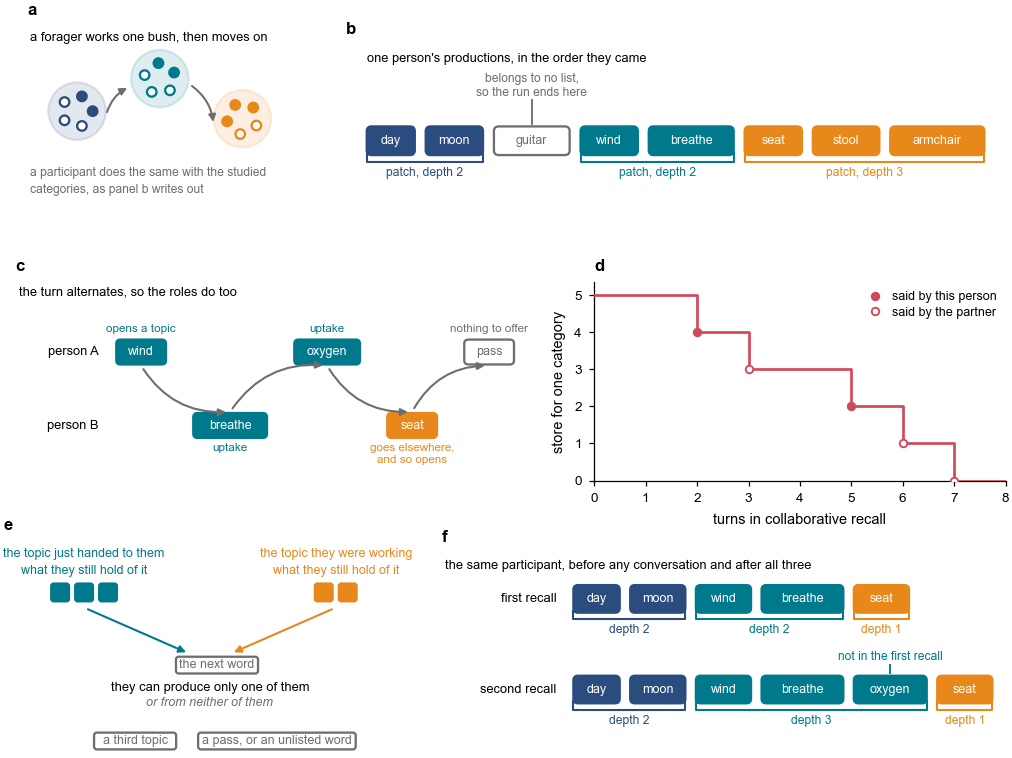

In [10]:
fig = plt.figure(figsize=(DOUBLE, 5.40))
gs = fig.add_gridspec(3, 2, height_ratios=[1.28, 1.30, 1.40],
                      width_ratios=[1.34, 1.00],
                      hspace=0.30, wspace=0.10,
                      left=0.035, right=0.985, top=0.970, bottom=0.070)

g0 = gs[0, :].subgridspec(1, 2, width_ratios=[1.00, 2.05], wspace=0.06)
g2 = gs[2, :].subgridspec(1, 2, width_ratios=[1.00, 1.35], wspace=0.06)
axa = fig.add_subplot(g0[0, 0])
axb = fig.add_subplot(g0[0, 1])
axc = fig.add_subplot(gs[1, 0])
axd = fig.add_subplot(gs[1, 1])
axe = fig.add_subplot(g2[0, 0])
axf = fig.add_subplot(g2[0, 1])

draw_analogy(axa)
draw_patch_rule(axb)
draw_roles(axc)
draw_store(axd)
draw_contest(axe)
draw_two_recalls(axf)

close_corner(fig)
for ax, L in ((axa, "a"), (axb, "b"), (axc, "c"), (axd, "d"), (axe, "e"), (axf, "f")):
    panel(ax, L)

save(fig, "Figure_1")
plt.show()